In [2]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

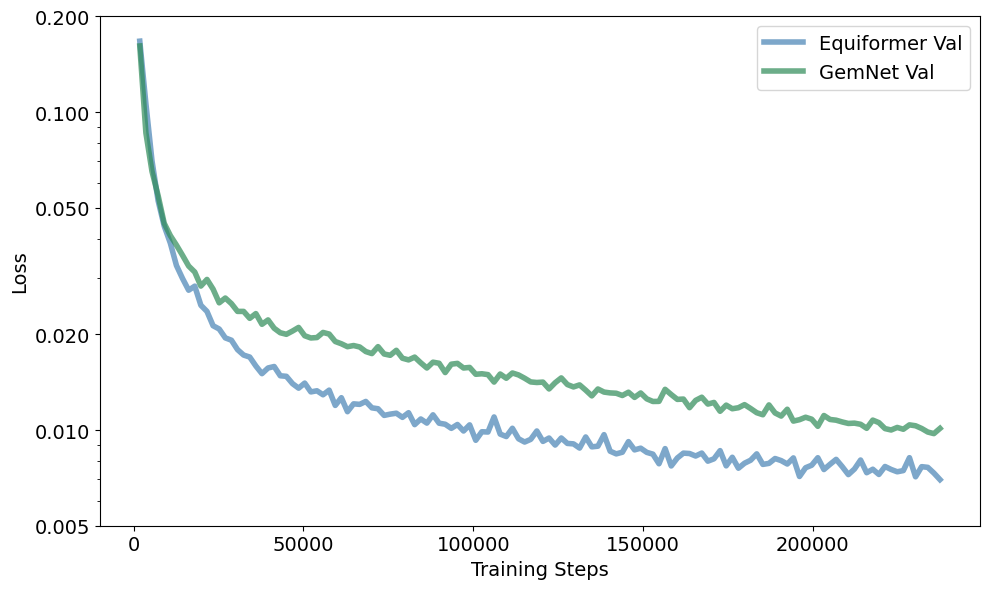

In [28]:
# Read the loss data
df = pd.read_csv('gemnet_equv2_loss.csv')

# Extract columns
steps = df['trainer/global_step']
equiformer_train_loss = df['equiformer-base - train/loss_epoch']
equiformer_val_loss = df['equiformer-base - val/loss']
gemnet_train_loss = df['gemnet-oc - train/loss_epoch']
gemnet_val_loss = df['gemnet-oc - val/loss']

# Find last valid index for equiformer data
last_valid_idx = equiformer_train_loss.last_valid_index()

# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps[:last_valid_idx+1], equiformer_val_loss[:last_valid_idx+1], label='Equiformer Val', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps[:last_valid_idx+1], gemnet_val_loss[:last_valid_idx+1], label='GemNet Val', color='seagreen', linewidth=4, alpha=0.7)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('gemnet_equv2_loss.pdf', dpi=300, bbox_inches='tight')